# Phase 6 — Synthetic BOLD Observation Models and HRF-Aware PLRNN

**Course:** Dynamical Systems in Machine Learning  
**Project:** Identifying Nonlinear Dynamical Systems via Generative Recurrent Neural Networks  
**Study:** Controlled hemodynamic observation comparison and exploratory joint-MAP latent inference.

**Critical scope:** The BOLD data in this notebook are **synthetic**. We apply an illustrative hemodynamic filter to normalized Van der Pol and Lorenz ODE trajectories used as **neural activity proxies**. The trajectories are **not actual neural recordings** and their integration time step is **not** a physiological fMRI repetition time (TR). We map one proxy sample to one illustrative TR=1 s for the observation experiment. This is a demonstration of the observation mechanism, **not real-human-fMRI analysis**.

This experiment extends Koppe et al. (2019), Eq. 3, but our latent model is **alternating joint-MAP**, not the paper's Laplace-EM or its inference of posterior covariances.

## 1. Mathematical model

The PLRNN dynamics remain

$$
 z_{t+1}=A z_t+W\operatorname{ReLU}(z_t)+b+\varepsilon_t,
$$

where $A$ is diagonal and $W$ has a zero diagonal. In this phase, the measurement model for BOLD is

$$
 y_t = B\sum_{k=0}^{L-1}h_k z_{t-k}+\eta_t,
 \qquad \eta_t\sim\mathcal N(0,\Gamma).
$$

$h_k$ is a **causal double-gamma HRF** whose sampled weights sum to one. The matched control model replaces the kernel $h$ with a unit impulse $\delta_{k0}$:

$$
 y_t^{\mathrm{instantaneous}} = B z_t+\eta_t.
$$

Both PLRNN variants use the same dynamics equation, architecture, latent dimension, data split, optimizer and schedule. The comparison isolates the change in the observation operator. The HRF implementation is pedagogical, not an exact implementation of SPM's reference routine. External task inputs and nuisance covariates are not included.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Open from the repository root or notebooks folder'
sys.path.insert(0, str(ROOT))
from src.data.bold import canonical_hrf, causal_convolution
from src.training.run_phase6 import run_phase6

RUN_EXPERIMENTS = False  # True retrains 4 models; by default use supplied validated outputs
RESULTS = ROOT / 'results' / 'phase6'
print('Project root:', ROOT)
print('Output directory:', RESULTS)


Project root: c:\PLRNN-Project
Output directory: c:\PLRNN-Project\results\phase6


## 2. Synthetic-data construction and train/test split

Each source is the **clean**, previously standardized Phase-1 benchmark trajectory (`x_true`, shape [1000,2] for Van der Pol and [1000,3] for Lorenz). We generate a BOLD-like signal using (a) a fixed spatial mixing matrix, (b) causal temporal HRF convolution, and (c) independent measurement noise of 5% of the **training** clean-BOLD standard deviation.

The split is 700 training points / 300 held-out points. The BOLD mean and standard deviation are computed **only using training observations**. Causal convolution is applied across the train/test boundary using earlier samples as physical history; **no future observations are accessed**. These are not independent human trials or subjects.

When the notebook loads the precomputed experiment, **no retraining occurs**.

In [2]:
if RUN_EXPERIMENTS:
    run_phase6(quick=False, skip_map=False, seed=42)

summary_path = RESULTS / 'metrics' / 'phase6_summary.json'
if not summary_path.exists():
    raise FileNotFoundError('Copy the Phase-6 ZIP contents into the repository root, or set RUN_EXPERIMENTS=True.')
results = json.loads(summary_path.read_text(encoding='utf-8'))
for key, r in results.items():
    print(key, ': train', r['train_end'], 'test', r['test_length'],
          '| HRF length', r['hrf_length'], 'illustrative TR', r['tr_illustrative'])


van_der_pol : train 700 test 300 | HRF length 32 illustrative TR 1.0
lorenz : train 700 test 300 | HRF length 32 illustrative TR 1.0


## 3. HRF and the delayed / smoothed signal

Synthetic BOLD example: van_der_pol


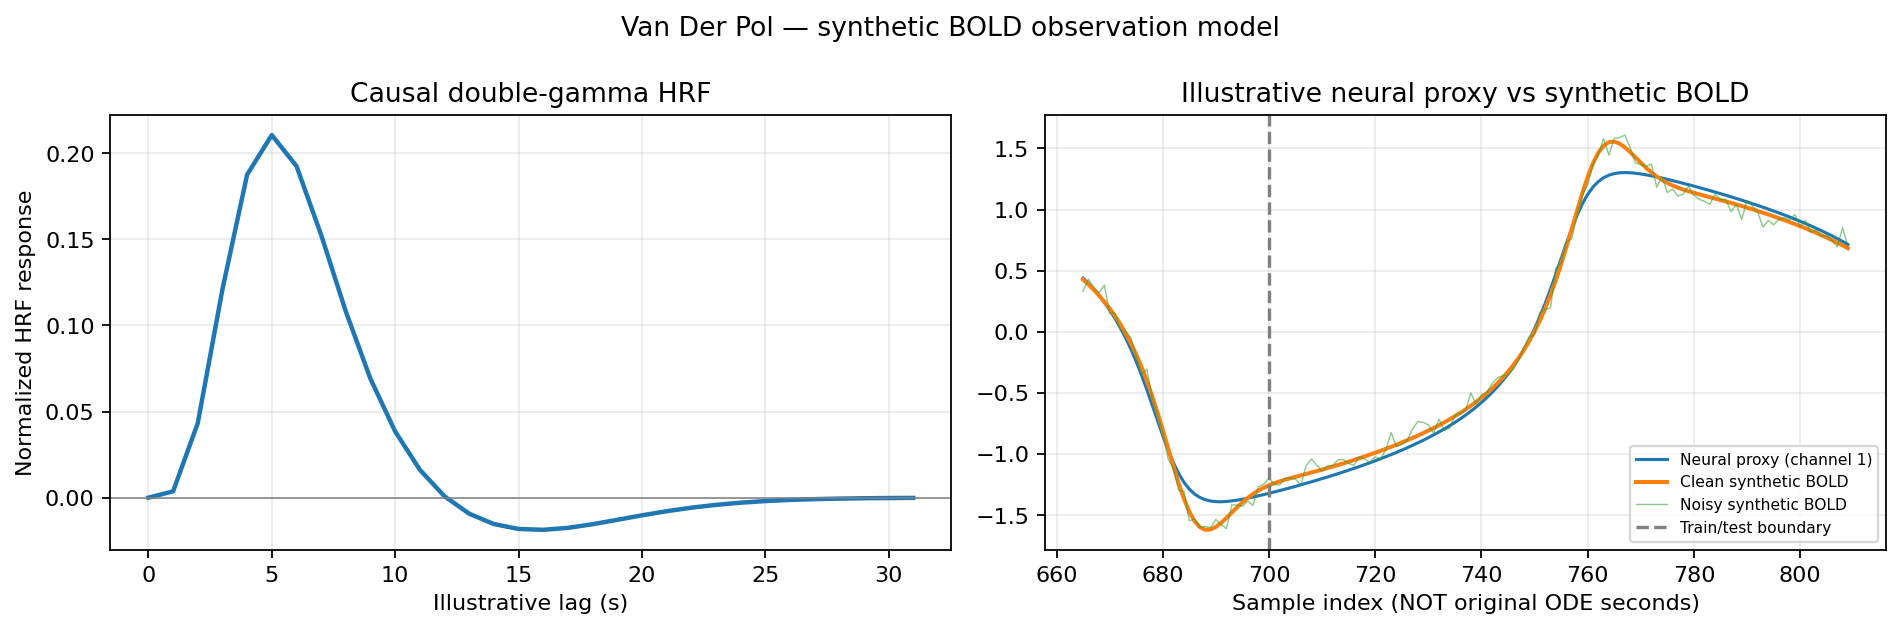

Synthetic BOLD example: lorenz


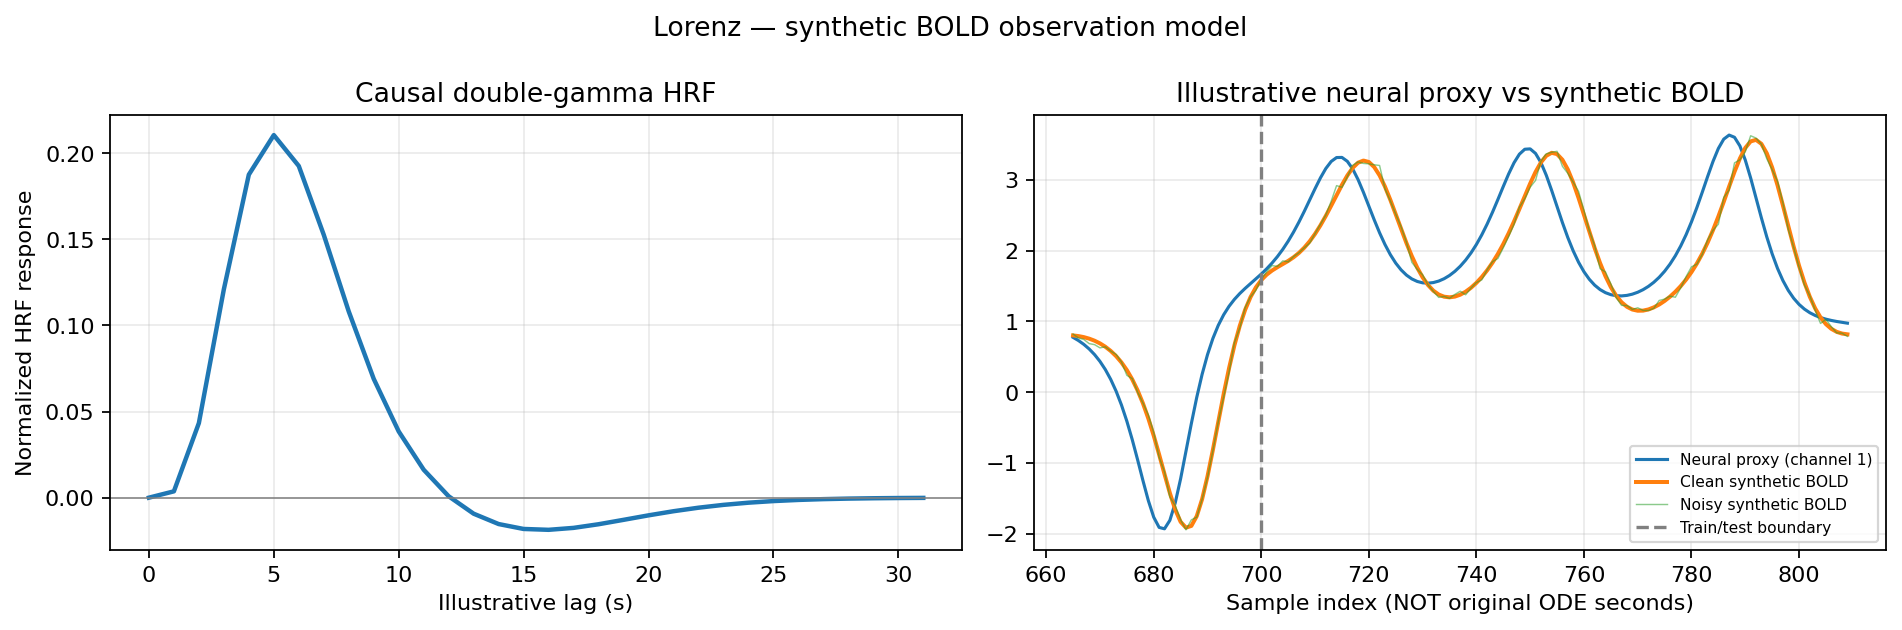

In [3]:
for name in ('van_der_pol', 'lorenz'):
    print('Synthetic BOLD example:', name)
    display(Image(filename=str(RESULTS/'figures'/f'phase6_{name}_hrf.png')))


## 4. Controlled observation-model ablation (known latent proxies)

The **oracle** comparison isolates the measurement equation from latent-state estimation. The benchmark proxy $u_t$ is supplied as a known regressor. We fit an intercept and a ridge-regularized matrix $B$ **using training measurements only**:

$$
 \min_{B,b}\sum_{t=1}^{T_\mathrm{train}}\|y_t - B\,\mathcal H(u)_t -b\|_2^2
 +\lambda\|B\|_F^2.
$$

Here $\mathcal H$ is either the HRF convolution or the identity map. Both linear decoders have **the same number of parameters**; only the temporal transformation differs.

The main metric compares the test prediction against the underlying **noise-free synthetic BOLD**, isolating model mismatch. We also report test error against the noisy observations. This is a known-state **decoder** experiment, **not** inference from fMRI.

,System,Observation model,Test MSE vs clean BOLD,Test MSE vs noisy BOLD,Train MSE vs noisy BOLD
0,Van Der Pol,hrf_aware,0.000011,0.002582,0.002475
1,Van Der Pol,instantaneous,0.121078,0.125254,0.125786
2,Lorenz,hrf_aware,0.000083,0.002658,0.002478
3,Lorenz,instantaneous,0.550267,0.551792,0.233443


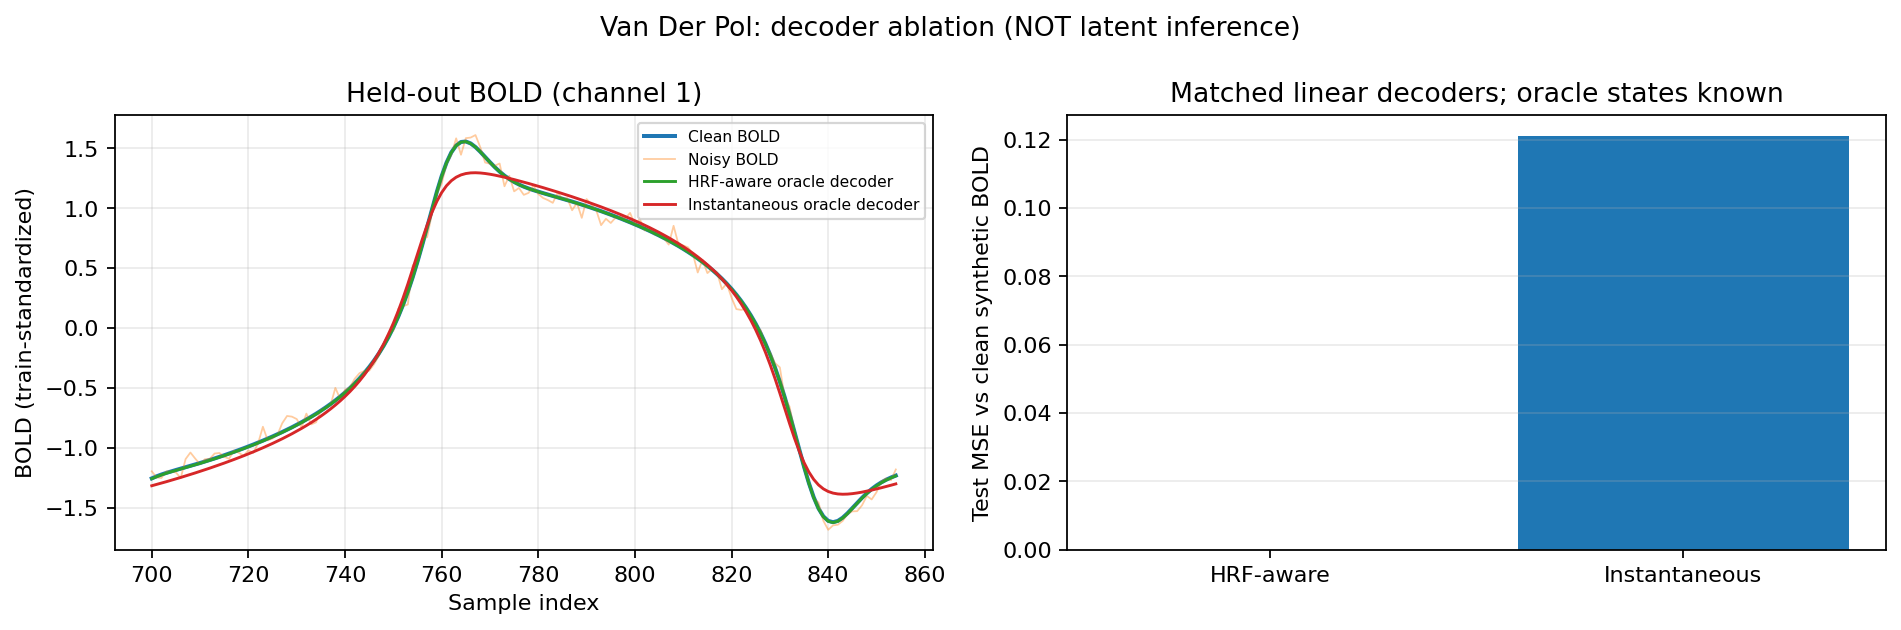

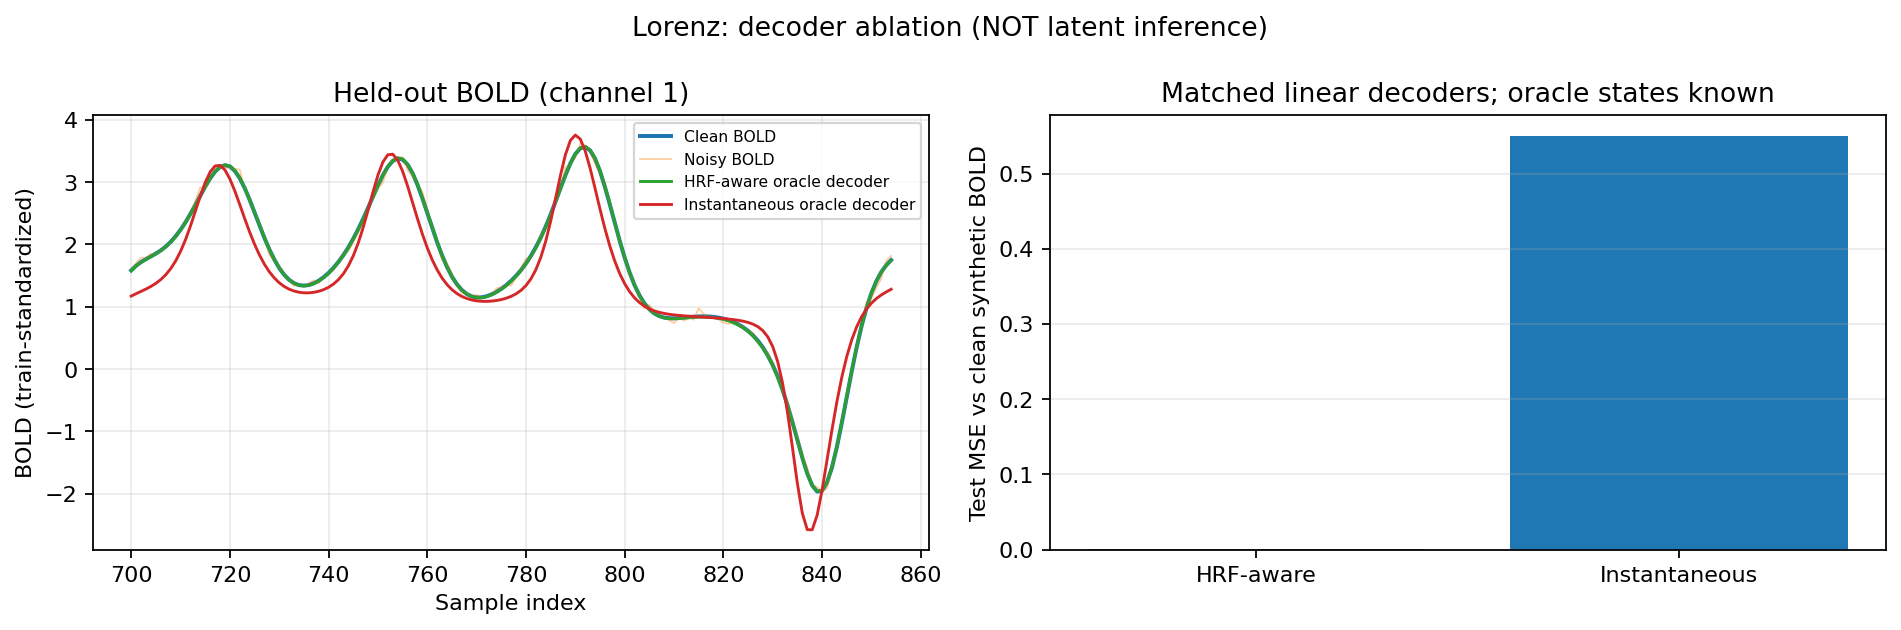

In [4]:
rows=[]
for system, rec in results.items():
    for approach, score in rec['oracle_decoder'].items():
        rows.append({'System':system.replace('_',' ').title(),
                     'Observation model':approach,
                     'Test MSE vs clean BOLD':score['test_clean'],
                     'Test MSE vs noisy BOLD':score['test_noisy'],
                     'Train MSE vs noisy BOLD':score['train_noisy']})
oracle_frame = pd.DataFrame(rows)
display(oracle_frame.round(6))
for name in ('van_der_pol','lorenz'):
    display(Image(filename=str(RESULTS/'figures'/f'phase6_{name}_oracle.png')))


## 5. Exploratory PLRNN-BOLD state-space approximation

We now fit **both** the latent path $z_{1:T}$ and PLRNN parameters $(A,W,b,B)$ using only **training BOLD measurements**. We alternate between:

1. **MAP-like latent optimization**: optimize all training states with a convolution-aware observation loss and a one-step dynamical consistency loss, using PyTorch automatic differentiation.
2. **Constrained regression updates**: regress the decoder on either convolved or instantaneous inferred states, and regress each latent transition with $A$ diagonal and $W$ zero-diagonal.

$$
\mathcal L_{\mathrm{MAP}}(Z;\theta) =
\frac{1}{T\,\sigma_y^2}\sum_{t=1}^T
 \|y_t-B\,\mathcal H(z)_t\|_2^2
+\frac{1}{(T-1)\,\sigma_z^2}\sum_{t=1}^{T-1}
\|z_{t+1}-F_\theta(z_t)\|_2^2.
$$

A process-variance schedule progressively weights dynamics. This is **not** the original Laplace-EM algorithm, does **not** infer exact/posterior state distributions and does **not** replicate all of Koppe et al.'s methods. The experiment contains no real task events, stimuli or movement regressors.

We independently generate 300 samples starting from the final *training* latent state. For HRF decoding, we continue convolution using the trailing **training** latent history. We report a smoothed histogram Jensen-Shannon divergence (JSD) in the same observed coordinates. JSD is **not** the paper's normalized KL. If a trajectory diverges, we flag it instead of silently omitting it.

,System,Model,Train observation MSE,Stable rollout,Held-out autonomous JSD,Held-out autonomous KL (raw)
0,Van Der Pol,hrf_aware,0.00195,True,0.12286,1.22848
1,Van Der Pol,instantaneous,0.00158,True,0.23773,3.07914
2,Lorenz,hrf_aware,0.00251,False,NaN,NaN
3,Lorenz,instantaneous,0.00136,True,0.57121,7.14322


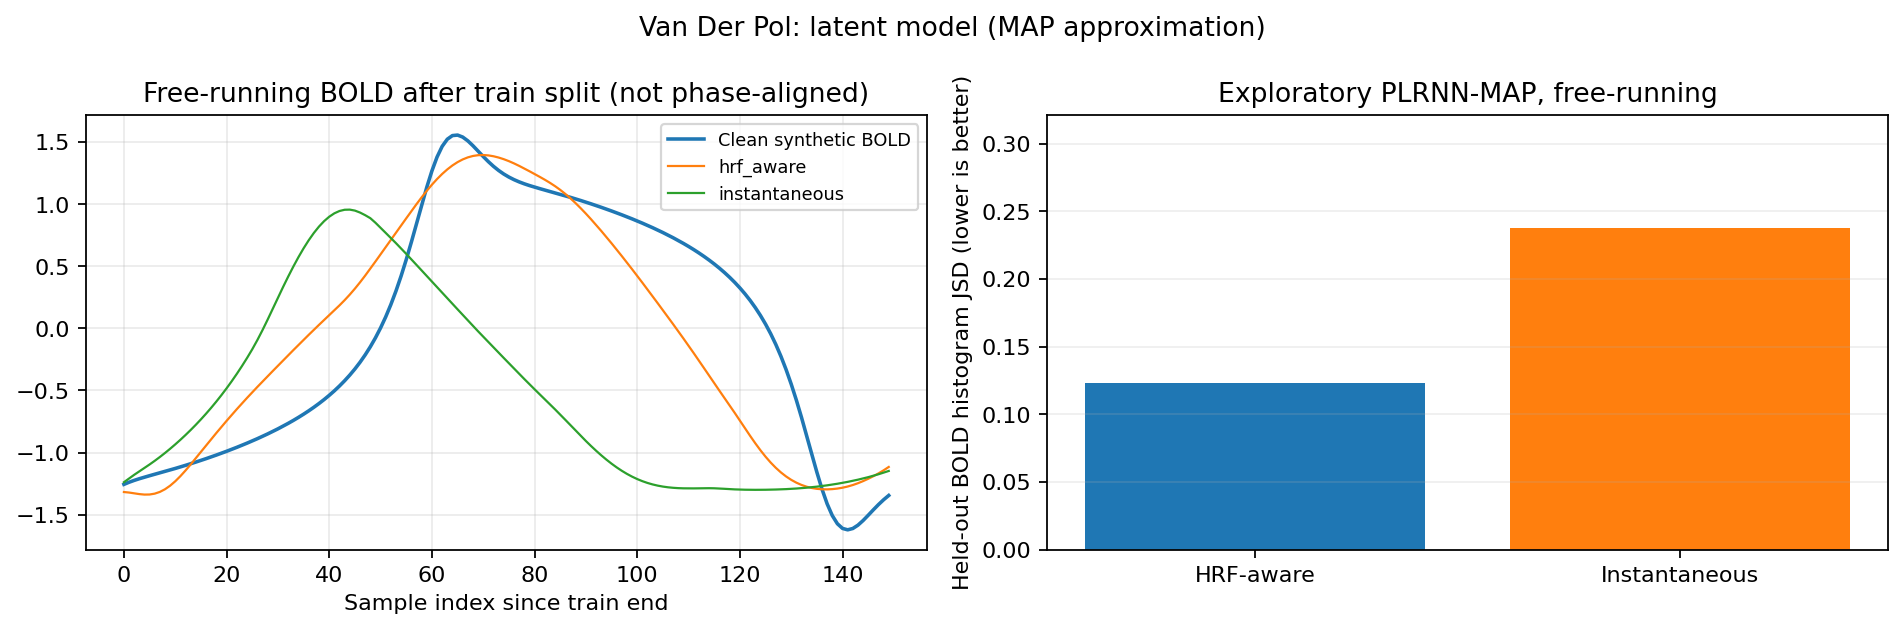

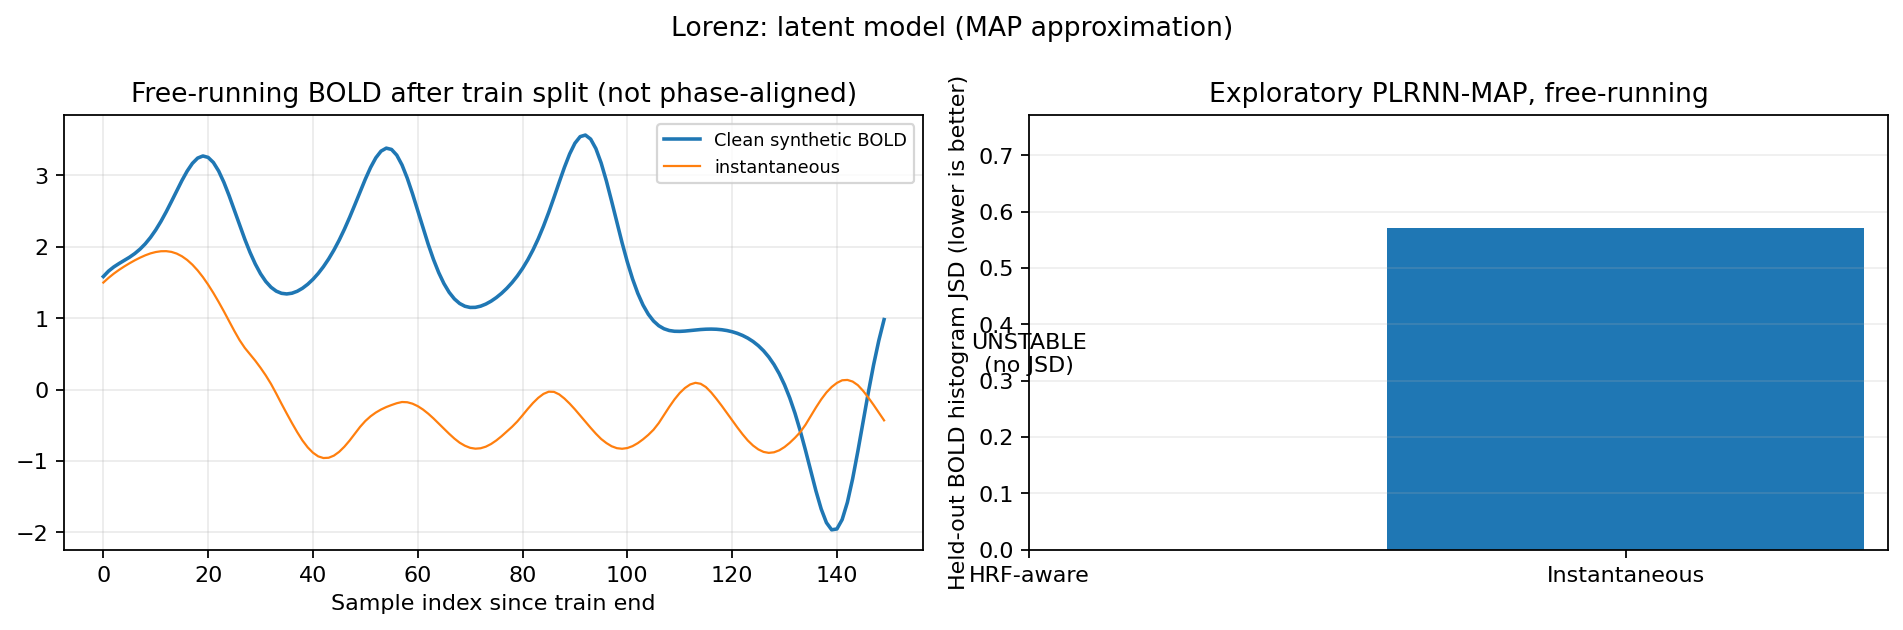

In [5]:
rows=[]
for system, rec in results.items():
    for name, score in rec.get('latent_map', {}).items():
        rows.append({'System':system.replace('_',' ').title(),
                     'Model':name,
                     'Train observation MSE':score['train_mse'],
                     'Stable rollout':score['stable'],
                     'Held-out autonomous JSD':score['test_js'],
                     'Held-out autonomous KL (raw)':score['test_kl_raw']})
map_frame=pd.DataFrame(rows)
display(map_frame.round(5))
for name in ('van_der_pol','lorenz'):
    display(Image(filename=str(RESULTS/'figures'/f'phase6_{name}_map.png')))


## 6. Interpretation

**Known proxy states:** Both systems favor the HRF-aware decoder by a large margin. This is expected, because the synthetic data-generating observation model explicitly uses the same HRF. The result validates the convolution implementation and shows how an inappropriate instantaneous observation model induces systematic errors.

**Unknown latent states (PLRNN-MAP):** For the included full run, the HRF-aware variant reduces autonomous BOLD distribution JSD on Van der Pol. For Lorenz, its autonomous generation becomes unstable after part of the held-out horizon. The instantaneous model is also not a faithful reconstruction of the latent Lorenz attractor. Do not claim that an HRF-aware PLRNN universally improves dynamic identification based on these two examples.

**Key distinction:** recovering $p(y_t\mid z_{1:t})$ when the latent states are known is very different from identifying the latent-generating law $p(z_{t+1}\mid z_t)$ from indirect, smoothed observations.

**Limits:** single benchmark trajectory per system, single seed for the MAP experiment, artificially constructed neural proxies, limited sample size, no actual human fMRI, no neural or cognitive meaning assigned to inferred states, simplified MAP not original posterior-based inference, no task/nuisance covariates, and a pedagogical HRF rather than a calibrated imaging pipeline.

## 7. Reproduction and next steps

In [6]:
print('Re-run commands (Windows PowerShell, from project root):')
print(r'python -m pip install -r requirements-phase6.txt')
print(r'python -m unittest discover -s tests -v')
print(r'python -m src.training.run_phase6 --quick  # quick MAP smoke test')
print(r'python -m src.training.run_phase6          # full experiment')
print('All outputs are synthetic; neither command changes earlier phases.')


Re-run commands (Windows PowerShell, from project root):
python -m pip install -r requirements-phase6.txt
python -m unittest discover -s tests -v
python -m src.training.run_phase6 --quick  # quick MAP smoke test
python -m src.training.run_phase6          # full experiment
All outputs are synthetic; neither command changes earlier phases.


**Suggested report section:** *Synthetic BOLD Observation Modelling and its Effect on Dynamical Identification.*

**Next stage:** If accessible and appropriately documented, move to actual preprocessed fMRI ROI time series with sampling interval, events, movement confounds and subject-level splits. Validate that the HRF implementation matches the acquisition protocol; reconsider higher-quality inference and model selection on training/validation subjects before any clinical or cognitive interpretation. Without such data, retain this synthetic result as an illustrative methodological extension, not an actual fMRI application.